In [3]:
from pathlib import Path
import copy
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights,
    swin_t,
    Swin_T_Weights,
    resnet50,
    ResNet50_Weights,
    efficientnet_b0,
    EfficientNet_B0_Weights,
)

DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)

## 1. Confirming CUDA is being used

In [4]:
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", GPU_NAME)

PyTorch: 2.14.0+cu130
CUDA build: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 2. Reproducibility

In [5]:
SEED = 42

def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

reset_seed()

## 3. Finding the AutoVision project root

In [6]:
def find_project_root(start=None):
    start = (start or Path.cwd()).resolve()

    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate

    raise FileNotFoundError(
        "Could not find the AutoVision project root containing pyproject.toml."
    )

PROJECT_ROOT = find_project_root()

REPORT_DIR = PROJECT_ROOT / "reports" / "colour_architecture_benchmark"
MODEL_DIR = PROJECT_ROOT / "models" / "colour_architecture_benchmark"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
INTERIM_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Reports:", REPORT_DIR)
print("Models:", MODEL_DIR)

Project root: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development
Reports: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\reports\colour_architecture_benchmark
Models: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\models\colour_architecture_benchmark


## 4. Locating `compcars_surveillance_inventory_v2.csv`

In [7]:
CSV_PATH = None

candidate_csvs = [
    PROJECT_ROOT / "data" / "processed" / "compcars_surveillance_inventory_v2.csv",
    PROJECT_ROOT / "data" / "external" / "compcars_surveillance_inventory_v2.csv",
    PROJECT_ROOT / "compcars_surveillance_inventory_v2.csv",

    Path(
        r"G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J"
        r"\capstone-vehicle-metadata\outputs\compcars_surveillance_inventory_v2.csv"
    ),

    Path(
        r"G:\My Drive\capstone-vehicle-metadata\outputs"
        r"\compcars_surveillance_inventory_v2.csv"
    ),
]

for candidate in candidate_csvs:
    if candidate.exists():
        CSV_PATH = candidate
        break

print("CSV_PATH:", CSV_PATH)

if CSV_PATH is None:
    raise FileNotFoundError(
        "Could not automatically locate compcars_surveillance_inventory_v2.csv. "
        "Set CSV_PATH manually to the teammate-prepared CSV."
    )

CSV_PATH: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\data\processed\compcars_surveillance_inventory_v2.csv


## 5. Loading and validating the prepared surveillance inventory

In [8]:
df = pd.read_csv(CSV_PATH)

required_columns = {
    "file_path",
    "color",
    "image_hash",
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"CSV is missing required columns: {sorted(missing_columns)}"
    )

print("Rows:", len(df))
print("Columns:", list(df.columns))
print()
print("Colour counts:")
print(df["color"].value_counts(dropna=False))

Rows: 44481
Columns: ['file_path', 'surveillance_model_id', 'make', 'model', 'web_model_id', 'color', 'width', 'height', 'corrupted', 'image_hash', 'source_dataset', 'body_type', 'parent_brand']

Colour counts:
color
black           14911
silver          12569
white            7570
red              3627
blue             1876
brown            1460
yellow           1123
champagne         829
green             255
purple            221
unrecognized       40
Name: count, dtype: int64


## 6. Resolving Colab image paths

In [9]:
SURVEILLANCE_ROOT_CANDIDATES = [
    Path(
        r"G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J"
        r"\capstone-vehicle-metadata\data\compcars_sv\extracted"
    ),
    Path(
        r"G:\My Drive\capstone-vehicle-metadata\data\compcars_sv\extracted"
    ),
]

SURVEILLANCE_ROOT = next(
    (p for p in SURVEILLANCE_ROOT_CANDIDATES if p.exists()),
    None,
)

print("Local surveillance root:", SURVEILLANCE_ROOT)

def resolve_image_path(raw_path):
    raw_path = str(raw_path)

    direct = Path(raw_path)
    if direct.exists():
        return direct

    normalized = raw_path.replace("\\", "/")

    marker = "/sv_data/"
    if marker in normalized and SURVEILLANCE_ROOT is not None:
        suffix = normalized.split(marker, 1)[1]
        return SURVEILLANCE_ROOT / "sv_data" / Path(*suffix.split("/"))

    return direct

df["resolved_path"] = df["file_path"].map(resolve_image_path)

exists_mask = df["resolved_path"].map(Path.exists)

print("Paths resolved:", int(exists_mask.sum()), "/", len(df))
print("Missing:", int((~exists_mask).sum()))

if not exists_mask.all():
    display(
        df.loc[
            ~exists_mask,
            ["file_path", "resolved_path", "color"]
        ].head(20)
    )

Local surveillance root: G:\.shortcut-targets-by-id\1OOvt005TduvEA8h6_snfuyQtbQAjo-3J\capstone-vehicle-metadata\data\compcars_sv\extracted
Paths resolved: 44481 / 44481
Missing: 0


## 7. Prepare recognised colour classes

In [10]:
colour_df = df.copy()

colour_df = colour_df[
    colour_df["resolved_path"].map(Path.exists)
].copy()

colour_df["color"] = (
    colour_df["color"]
    .astype(str)
    .str.strip()
    .str.lower()
)

colour_df = colour_df[
    colour_df["color"].notna()
    & (colour_df["color"] != "unrecognized")
    & (colour_df["color"] != "nan")
].copy()

print("Usable recognised-colour rows:", len(colour_df))
print("Colour classes:", colour_df["color"].nunique())
print()
print(colour_df["color"].value_counts())

Usable recognised-colour rows: 44441
Colour classes: 10

color
black        14911
silver       12569
white         7570
red           3627
blue          1876
brown         1460
yellow        1123
champagne      829
green          255
purple         221
Name: count, dtype: int64


## 8. Checking exact duplicates before splitting

In [11]:
duplicate_hashes = colour_df["image_hash"].duplicated().sum()

print("Duplicate image hashes:", duplicate_hashes)

if duplicate_hashes > 0:
    print(
        "Removing exact duplicate images before sampling so identical images "
        "cannot appear across train/validation/test."
    )

    colour_df = (
        colour_df
        .drop_duplicates(subset="image_hash", keep="first")
        .copy()
    )

print("Rows after duplicate check:", len(colour_df))

Duplicate image hashes: 0
Rows after duplicate check: 44441


## 9. Building the controlled benchmark

In [12]:
IMAGES_PER_CLASS = 100

counts = colour_df["color"].value_counts()

too_small = counts[counts < IMAGES_PER_CLASS]

if len(too_small) > 0:
    raise ValueError(
        "Some colour classes do not have enough images for the controlled benchmark:\n"
        + too_small.to_string()
    )

sampled_parts = []

for colour_name in sorted(colour_df["color"].unique()):
    class_rows = colour_df[
        colour_df["color"] == colour_name
    ]

    sampled_parts.append(
        class_rows.sample(
            n=IMAGES_PER_CLASS,
            random_state=SEED,
        )
    )

benchmark_df = pd.concat(
    sampled_parts,
    ignore_index=True,
)

class_names = sorted(
    benchmark_df["color"].unique()
)

class_to_idx = {
    label: idx
    for idx, label in enumerate(class_names)
}

benchmark_df["target"] = (
    benchmark_df["color"]
    .map(class_to_idx)
    .astype(int)
)

print("Classes:", class_names)
print("Total benchmark images:", len(benchmark_df))
print(benchmark_df["color"].value_counts().sort_index())

Classes: ['black', 'blue', 'brown', 'champagne', 'green', 'purple', 'red', 'silver', 'white', 'yellow']
Total benchmark images: 1000
color
black        100
blue         100
brown        100
champagne    100
green        100
purple       100
red          100
silver       100
white        100
yellow       100
Name: count, dtype: int64


## 10. Stratified split

In [13]:
train_df, temp_df = train_test_split(
    benchmark_df,
    test_size=0.20,
    random_state=SEED,
    stratify=benchmark_df["target"],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["target"],
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

split_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True,
)

print(
    "Train / Val / Test:",
    len(train_df),
    len(val_df),
    len(test_df),
)

display(
    split_df.groupby(["color", "split"])
    .size()
    .unstack(fill_value=0)
)

train_hashes = set(train_df["image_hash"])
val_hashes = set(val_df["image_hash"])
test_hashes = set(test_df["image_hash"])

assert train_hashes.isdisjoint(val_hashes)
assert train_hashes.isdisjoint(test_hashes)
assert val_hashes.isdisjoint(test_hashes)

SPLIT_PATH = INTERIM_DIR / "compcars_colour_controlled_split.csv"

split_df.to_csv(SPLIT_PATH, index=False)

print("Saved split:", SPLIT_PATH)

Train / Val / Test: 800 100 100


split,test,train,val
color,,,
black,10,80,10
blue,10,80,10
brown,10,80,10
champagne,10,80,10
green,10,80,10
purple,10,80,10
red,10,80,10
silver,10,80,10
white,10,80,10


Saved split: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\data\interim\compcars_colour_controlled_split.csv


## 11. Showing a small sample from each colour

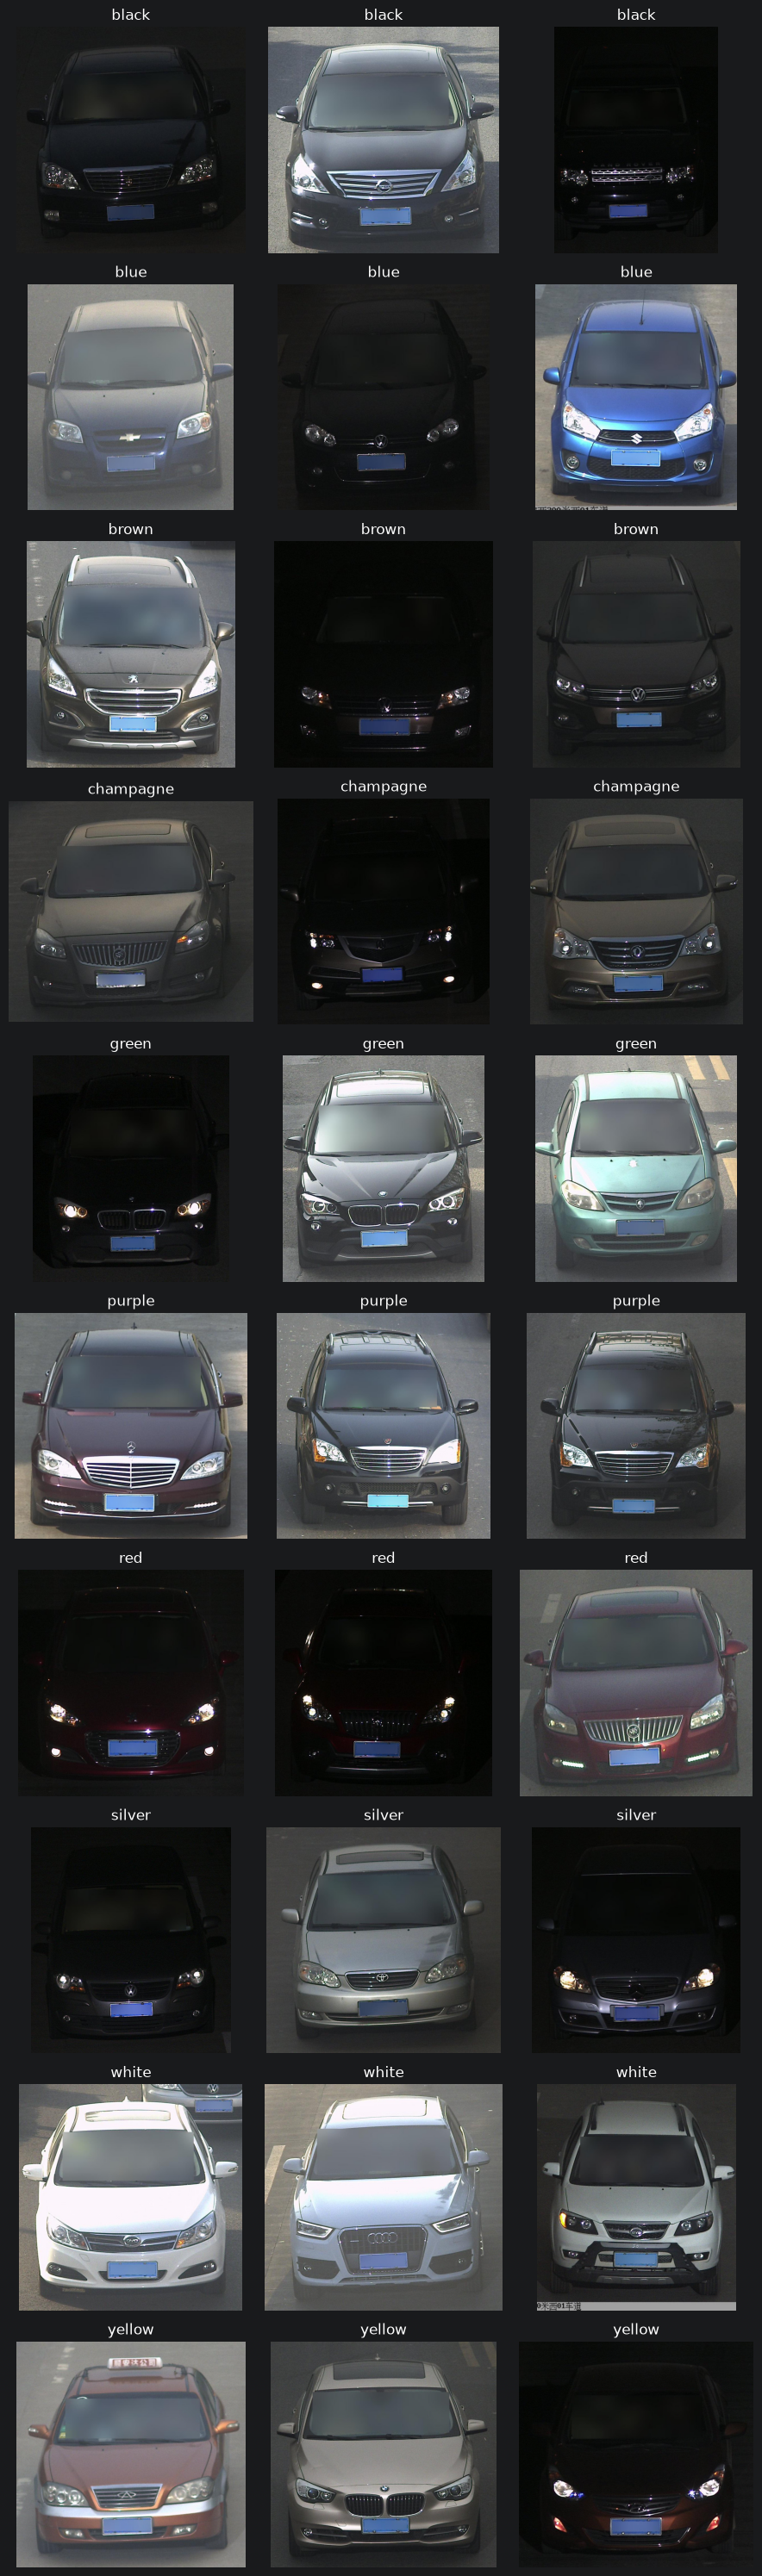

In [14]:
fig, axes = plt.subplots(
    len(class_names),
    3,
    figsize=(9, 3 * len(class_names)),
)

for row_idx, colour_name in enumerate(class_names):
    examples = (
        train_df[
            train_df["color"] == colour_name
        ]
        .sample(
            n=3,
            random_state=SEED,
        )
        .reset_index(drop=True)
    )

    for col_idx, row in examples.iterrows():
        image = Image.open(row["resolved_path"]).convert("RGB")

        axes[row_idx, col_idx].imshow(image)
        axes[row_idx, col_idx].axis("off")
        axes[row_idx, col_idx].set_title(colour_name)

plt.tight_layout()
plt.show()

## 12. Colour-safe preprocessing

In [15]:
IMAGE_SIZE = 224

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.85, 1.0),
        ratio=(0.90, 1.10),
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

## 13. Dataset and DataLoaders

In [16]:
class ColourDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image = Image.open(
            row["resolved_path"]
        ).convert("RGB")

        image = self.transform(image)
        target = int(row["target"])

        return image, target


BATCH_SIZE = 16
NUM_WORKERS = 0

train_loader = DataLoader(
    ColourDataset(train_df, train_transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    ColourDataset(val_df, eval_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    ColourDataset(test_df, eval_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 50
Validation batches: 7
Test batches: 7


## 14. Architecture configurations

In [17]:
MODEL_CONFIGS = {
    "convnext_tiny": {
        "finetune_lr": 5e-5,
        "weight_decay": 1e-4,
        "label_smoothing": 0.1,
        "stage2_epochs": 5,
    },

    "swin_t": {
        "finetune_lr": 3e-5,
        "weight_decay": 1e-4,
        "label_smoothing": 0.1,
        "stage2_epochs": 6,
    },

    "resnet50": {
        "finetune_lr": 5e-4,
        "weight_decay": 1e-4,
        "label_smoothing": 0.1,
        "stage2_epochs": 3,
    },

    "efficientnet_b0": {
        "finetune_lr": 1e-4,
        "weight_decay": 1e-4,
        "label_smoothing": 0.1,
        "stage2_epochs": 7,
    },
}

MODELS_TO_RUN = [
    "convnext_tiny",
    "swin_t",
    "resnet50",
    "efficientnet_b0",
]

HEAD_LR = 1e-3
HEAD_EPOCHS = 3
NUM_CLASSES = len(class_names)

## 15. Model builders and fine-tuning depth

In [18]:
def build_model(model_name, num_classes):
    if model_name == "convnext_tiny":
        model = convnext_tiny(
            weights=ConvNeXt_Tiny_Weights.DEFAULT
        )

        for p in model.parameters():
            p.requires_grad = False

        model.classifier[2] = nn.Linear(
            model.classifier[2].in_features,
            num_classes,
        )

        head_parameters = model.classifier[2].parameters()

    elif model_name == "swin_t":
        model = swin_t(
            weights=Swin_T_Weights.DEFAULT
        )

        for p in model.parameters():
            p.requires_grad = False

        model.head = nn.Linear(
            model.head.in_features,
            num_classes,
        )

        head_parameters = model.head.parameters()

    elif model_name == "resnet50":
        model = resnet50(
            weights=ResNet50_Weights.DEFAULT
        )

        for p in model.parameters():
            p.requires_grad = False

        model.fc = nn.Linear(
            model.fc.in_features,
            num_classes,
        )

        head_parameters = model.fc.parameters()

    elif model_name == "efficientnet_b0":
        model = efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        for p in model.parameters():
            p.requires_grad = False

        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features,
            num_classes,
        )

        head_parameters = model.classifier[1].parameters()

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return model.to(DEVICE), head_parameters


def unfreeze_for_stage2(model, model_name):
    if model_name == "convnext_tiny":
        modules = [
            model.features[5],
            model.features[6],
            model.features[7],
            model.classifier,
        ]

    elif model_name == "swin_t":
        modules = [
            model.features[5],
            model.features[6],
            model.features[7],
            model.norm,
            model.head,
        ]

    elif model_name == "resnet50":
        modules = [
            model.layer4,
            model.fc,
        ]

    elif model_name == "efficientnet_b0":
        modules = [
            model.features[6],
            model.features[7],
            model.features[8],
            model.classifier,
        ]

    else:
        raise ValueError(model_name)

    for module in modules:
        for p in module.parameters():
            p.requires_grad = True

## 16. Training utilities

In [19]:
def topk_correct(logits, targets, k=5):
    k = min(k, logits.shape[1])

    topk = logits.topk(k, dim=1).indices

    return (
        topk
        .eq(targets.view(-1, 1))
        .any(dim=1)
        .sum()
        .item()
    )


def run_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    scaler=None,
):
    training = optimizer is not None

    model.train(training)

    total_loss = 0.0
    top1_correct = 0
    top5_correct = 0
    total_samples = 0

    for images, targets in tqdm(loader, leave=False):
        images = images.to(
            DEVICE,
            non_blocking=True,
        )

        targets = targets.to(
            DEVICE,
            non_blocking=True,
        )

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available(),
        ):
            logits = model(images)
            loss = criterion(logits, targets)

        if training:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size

        top1_correct += (
            logits.argmax(dim=1) == targets
        ).sum().item()

        top5_correct += topk_correct(
            logits,
            targets,
            k=5,
        )

        total_samples += batch_size

    return {
        "loss": total_loss / total_samples,
        "top1": top1_correct / total_samples,
        "top5": top5_correct / total_samples,
    }


def train_stage(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs,
    stage_name,
):
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available(),
    )

    history = []
    best_val_top1 = -1.0
    best_val_loss = float("inf")
    best_state = None

    for epoch in range(1, epochs + 1):
        started = time.perf_counter()

        train_metrics = run_epoch(
            model,
            train_loader,
            criterion,
            optimizer=optimizer,
            scaler=scaler,
        )

        with torch.inference_mode():
            val_metrics = run_epoch(
                model,
                val_loader,
                criterion,
            )

        elapsed = time.perf_counter() - started

        row = {
            "stage": stage_name,
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_top1": train_metrics["top1"],
            "val_loss": val_metrics["loss"],
            "val_top1": val_metrics["top1"],
            "val_top5": val_metrics["top5"],
            "seconds": elapsed,
        }

        history.append(row)

        print(
            f"[{stage_name}] {epoch}/{epochs} | "
            f"train={row['train_top1']:.3f} "
            f"val={row['val_top1']:.3f} "
            f"top5={row['val_top5']:.3f} "
            f"loss={row['val_loss']:.4f} | "
            f"{elapsed:.1f}s"
        )

        is_better = (
            row["val_top1"] > best_val_top1
            or (
                row["val_top1"] == best_val_top1
                and row["val_loss"] < best_val_loss
            )
        )

        if is_better:
            best_val_top1 = row["val_top1"]
            best_val_loss = row["val_loss"]
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)

    return (
        history,
        best_val_top1,
        best_val_loss,
        best_state,
    )

## 17. Test evaluation

In [20]:
def evaluate_model(model, loader):
    model.eval()

    y_true = []
    y_pred = []
    all_probabilities = []

    with torch.inference_mode():
        for images, targets in tqdm(loader, leave=False):
            images = images.to(
                DEVICE,
                non_blocking=True,
            )

            logits = model(images)
            probabilities = torch.softmax(logits, dim=1)

            y_true.extend(targets.numpy())
            y_pred.extend(
                probabilities.argmax(dim=1).cpu().numpy()
            )

            all_probabilities.append(
                probabilities.cpu()
            )

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    all_probabilities = torch.cat(
        all_probabilities,
        dim=0,
    )

    top1 = accuracy_score(y_true, y_pred)

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0,
    )

    k = min(5, all_probabilities.shape[1])

    topk_indices = (
        all_probabilities
        .topk(k, dim=1)
        .indices
        .numpy()
    )

    top5 = np.mean([
        true_label in candidate_labels
        for true_label, candidate_labels
        in zip(y_true, topk_indices)
    ])

    return {
        "top1": float(top1),
        "top5": float(top5),
        "macro_f1": float(macro_f1),
        "y_true": y_true,
        "y_pred": y_pred,
    }

## 17. Running the four-model colour benchmark


TASK: colour | MODEL: convnext_tiny
Classes: 10
Config: {'finetune_lr': 5e-05, 'weight_decay': 0.0001, 'label_smoothing': 0.1, 'stage2_epochs': 5}


[head] 1/3 | train=0.290 val=0.440 top5=0.880 loss=1.8810 | 999.1s


[head] 2/3 | train=0.496 val=0.510 top5=0.900 loss=1.6757 | 24.1s


[head] 3/3 | train=0.590 val=0.550 top5=0.930 loss=1.5624 | 22.0s


[fine_tune] 1/5 | train=0.720 val=0.780 top5=1.000 loss=1.0439 | 25.3s


[fine_tune] 2/5 | train=0.868 val=0.790 top5=1.000 loss=0.9814 | 23.7s


[fine_tune] 3/5 | train=0.941 val=0.860 top5=1.000 loss=0.8839 | 23.7s


[fine_tune] 4/5 | train=0.976 val=0.850 top5=1.000 loss=0.8772 | 23.8s


[fine_tune] 5/5 | train=0.988 val=0.840 top5=1.000 loss=0.8712 | 24.8s



FINAL: {'task': 'colour', 'model': 'convnext_tiny', 'num_classes': 10, 'num_train': 800, 'num_val': 100, 'num_test': 100, 'selected_stage': 'fine_tune', 'validation_top1': 0.86, 'validation_loss': 0.8838868856430053, 'test_top1': 0.85, 'test_top5': 0.99, 'test_macro_f1': 0.8489830637199057, 'gpu': 'NVIDIA GeForce RTX 5060 Laptop GPU'}


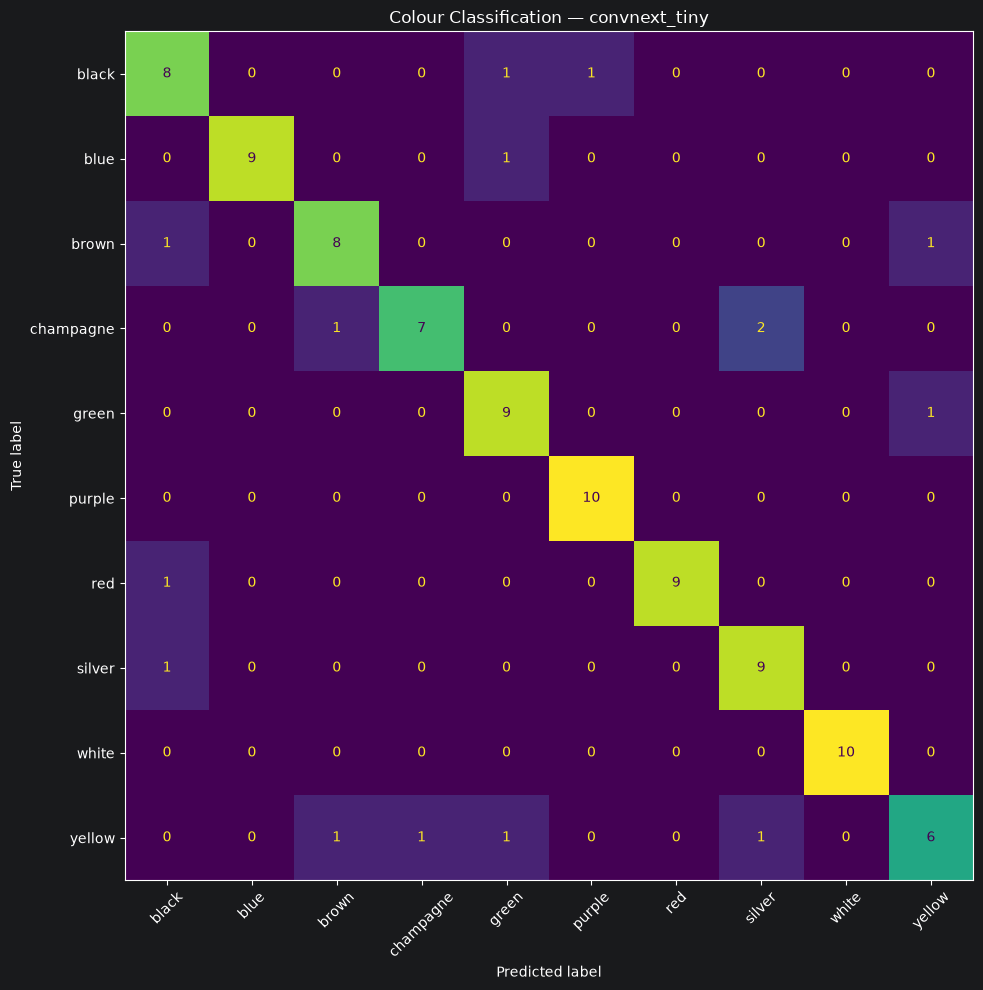


TASK: colour | MODEL: swin_t
Classes: 10
Config: {'finetune_lr': 3e-05, 'weight_decay': 0.0001, 'label_smoothing': 0.1, 'stage2_epochs': 6}


[head] 1/3 | train=0.251 val=0.470 top5=0.860 loss=1.9403 | 24.6s


[head] 2/3 | train=0.421 val=0.520 top5=0.850 loss=1.7560 | 24.8s


[head] 3/3 | train=0.549 val=0.580 top5=0.890 loss=1.6587 | 23.3s


[fine_tune] 1/6 | train=0.631 val=0.770 top5=0.990 loss=1.0924 | 28.6s


...

[fine_tune] 3/6 | train=0.829 val=0.860 top5=1.000 loss=0.9081 | 26.6s


[fine_tune] 4/6 | train=0.876 val=0.880 top5=1.000 loss=0.8726 | 28.0s


[fine_tune] 5/6 | train=0.884 val=0.870 top5=1.000 loss=0.8755 | 28.2s


[fine_tune] 6/6 | train=0.911 val=0.900 top5=1.000 loss=0.8517 | 30.3s



FINAL: {'task': 'colour', 'model': 'swin_t', 'num_classes': 10, 'num_train': 800, 'num_val': 100, 'num_test': 100, 'selected_stage': 'fine_tune', 'validation_top1': 0.9, 'validation_loss': 0.8516554307937622, 'test_top1': 0.82, 'test_top5': 1.0, 'test_macro_f1': 0.8224992432772751, 'gpu': 'NVIDIA GeForce RTX 5060 Laptop GPU'}


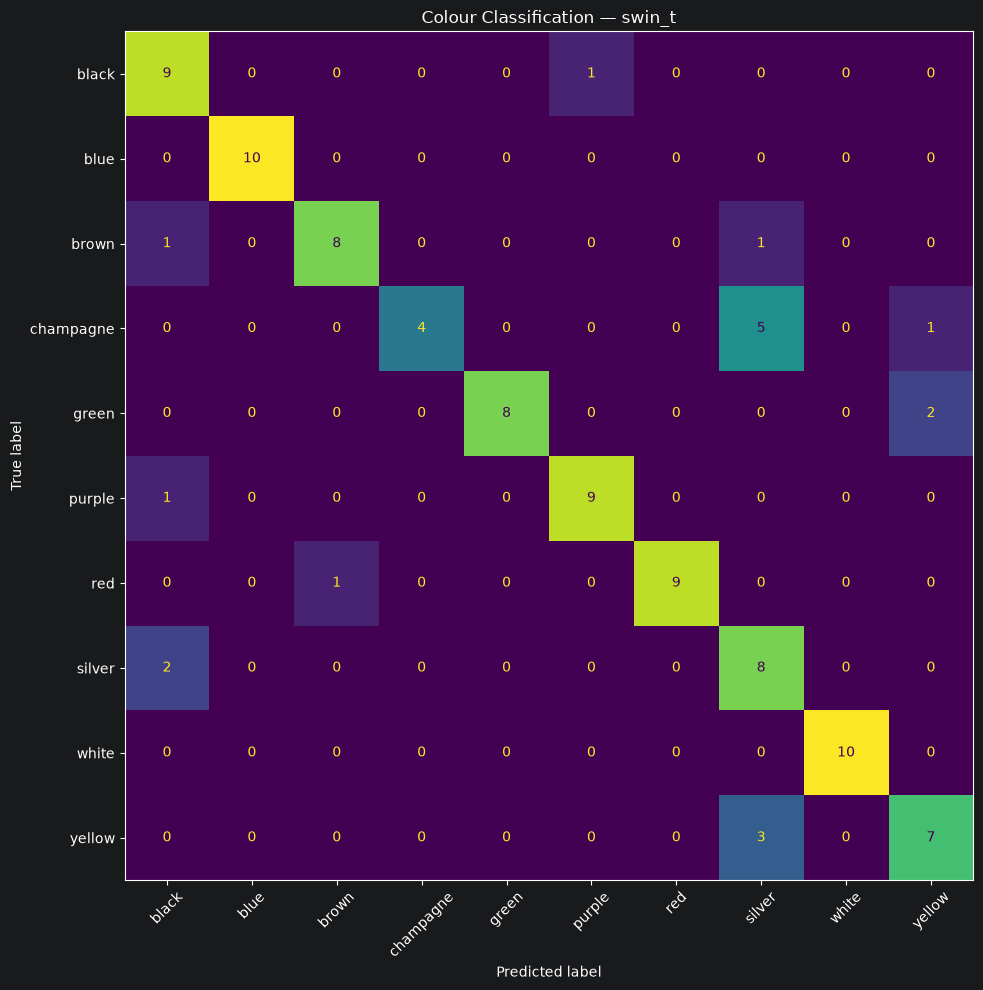


TASK: colour | MODEL: resnet50
Classes: 10
Config: {'finetune_lr': 0.0005, 'weight_decay': 0.0001, 'label_smoothing': 0.1, 'stage2_epochs': 3}


[head] 1/3 | train=0.301 val=0.500 top5=0.880 loss=1.9734 | 26.4s


[head] 2/3 | train=0.564 val=0.510 top5=0.930 loss=1.7853 | 23.6s


[head] 3/3 | train=0.632 val=0.580 top5=0.920 loss=1.6557 | 19.5s


[fine_tune] 1/3 | train=0.700 val=0.680 top5=0.970 loss=1.3154 | 20.1s


[fine_tune] 2/3 | train=0.894 val=0.730 top5=0.990 loss=1.0887 | 20.0s


[fine_tune] 3/3 | train=0.944 val=0.740 top5=0.980 loss=1.1021 | 20.1s



FINAL: {'task': 'colour', 'model': 'resnet50', 'num_classes': 10, 'num_train': 800, 'num_val': 100, 'num_test': 100, 'selected_stage': 'fine_tune', 'validation_top1': 0.74, 'validation_loss': 1.1020544934272767, 'test_top1': 0.79, 'test_top5': 0.99, 'test_macro_f1': 0.7981554429552141, 'gpu': 'NVIDIA GeForce RTX 5060 Laptop GPU'}


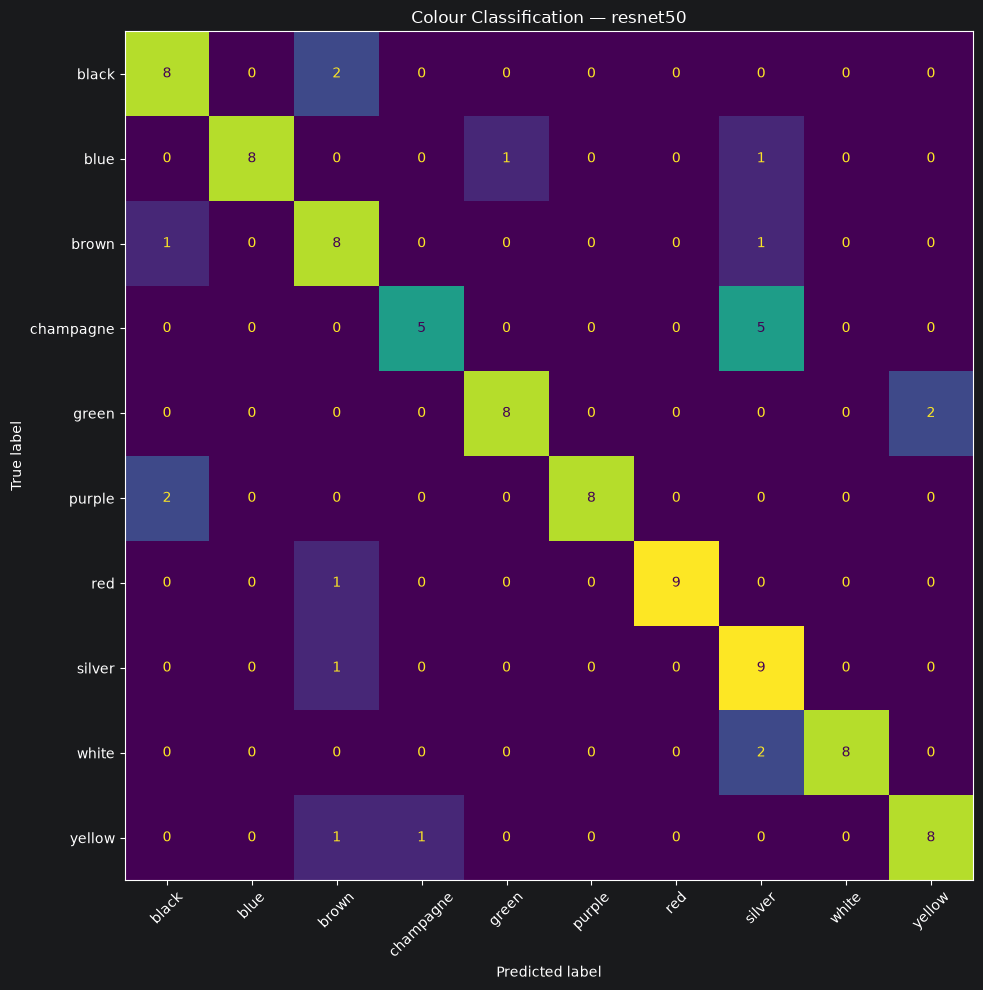


TASK: colour | MODEL: efficientnet_b0
Classes: 10
Config: {'finetune_lr': 0.0001, 'weight_decay': 0.0001, 'label_smoothing': 0.1, 'stage2_epochs': 7}


[head] 1/3 | train=0.307 val=0.440 top5=0.920 loss=1.8357 | 24.7s


[head] 2/3 | train=0.535 val=0.510 top5=0.970 loss=1.6125 | 22.3s


[head] 3/3 | train=0.605 val=0.580 top5=0.980 loss=1.5033 | 27.6s


[fine_tune] 1/7 | train=0.701 val=0.680 top5=1.000 loss=1.2363 | 31.2s


...

[fine_tune] 4/7 | train=0.860 val=0.770 top5=1.000 loss=0.9937 | 29.6s


[fine_tune] 5/7 | train=0.889 val=0.820 top5=1.000 loss=0.9644 | 26.9s


[fine_tune] 6/7 | train=0.919 val=0.860 top5=1.000 loss=0.9129 | 26.9s


[fine_tune] 7/7 | train=0.929 val=0.810 top5=1.000 loss=0.9526 | 27.1s



FINAL: {'task': 'colour', 'model': 'efficientnet_b0', 'num_classes': 10, 'num_train': 800, 'num_val': 100, 'num_test': 100, 'selected_stage': 'fine_tune', 'validation_top1': 0.86, 'validation_loss': 0.9128753423690796, 'test_top1': 0.76, 'test_top5': 0.99, 'test_macro_f1': 0.7529481681029668, 'gpu': 'NVIDIA GeForce RTX 5060 Laptop GPU'}


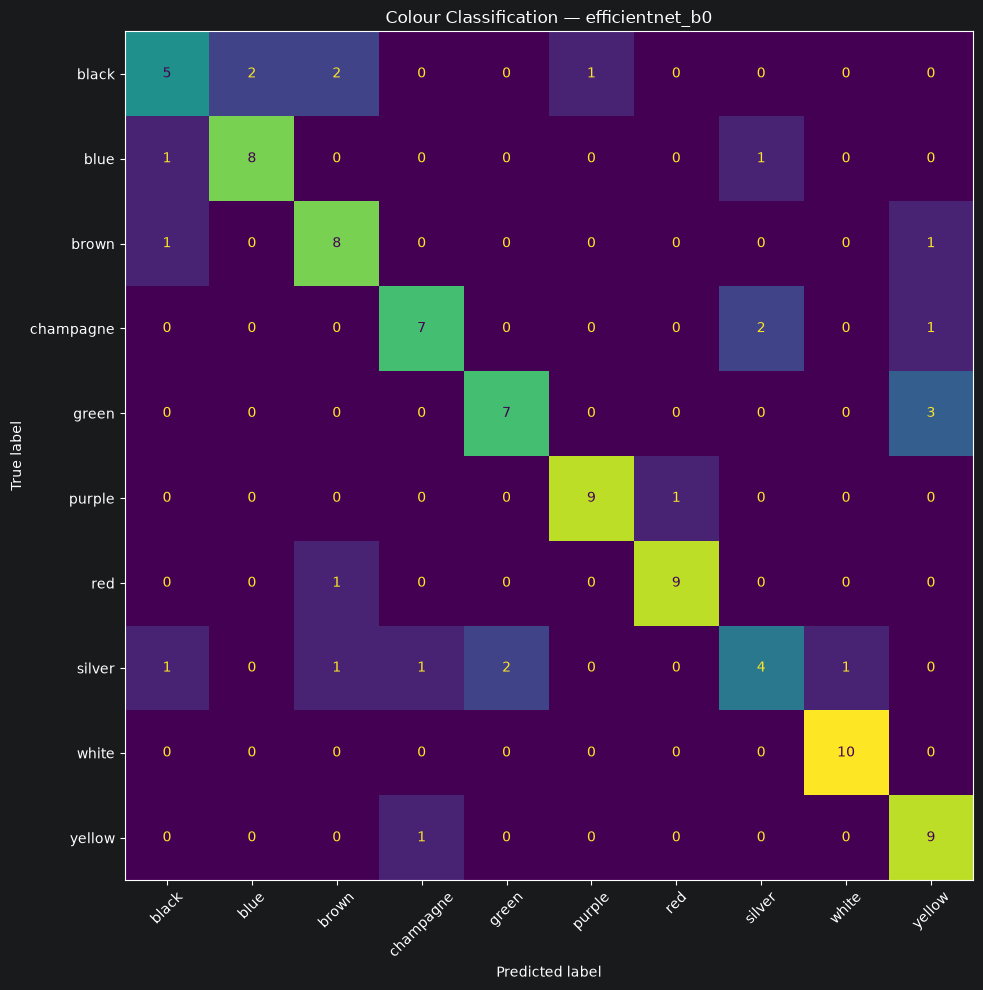

In [21]:
all_results = []
all_histories = []

for model_name in MODELS_TO_RUN:
    reset_seed()

    config = MODEL_CONFIGS[model_name]

    print("\n" + "=" * 90)
    print("TASK: colour | MODEL:", model_name)
    print("Classes:", NUM_CLASSES)
    print("Config:", config)
    print("=" * 90)

    model, head_parameters = build_model(
        model_name,
        NUM_CLASSES,
    )

    criterion = nn.CrossEntropyLoss(
        label_smoothing=config["label_smoothing"]
    )

    # Stage 1: classifier head
    optimizer = torch.optim.AdamW(
        head_parameters,
        lr=HEAD_LR,
        weight_decay=config["weight_decay"],
    )

    (
        head_history,
        head_val_top1,
        head_val_loss,
        head_state,
    ) = train_stage(
        model,
        train_loader,
        val_loader,
        criterion,
        optimizer,
        HEAD_EPOCHS,
        "head",
    )

    # Stage 2: fine-tuning-
    unfreeze_for_stage2(
        model,
        model_name,
    )

    optimizer = torch.optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters(),
        ),
        lr=config["finetune_lr"],
        weight_decay=config["weight_decay"],
    )

    (
        finetune_history,
        finetune_val_top1,
        finetune_val_loss,
        finetune_state,
    ) = train_stage(
        model,
        train_loader,
        val_loader,
        criterion,
        optimizer,
        config["stage2_epochs"],
        "fine_tune",
    )

    head_key = (
        head_val_top1,
        -head_val_loss,
    )

    finetune_key = (
        finetune_val_top1,
        -finetune_val_loss,
    )

    if head_key > finetune_key:
        selected_stage = "head"
        best_val_top1 = head_val_top1
        best_val_loss = head_val_loss
        best_state = head_state
    else:
        selected_stage = "fine_tune"
        best_val_top1 = finetune_val_top1
        best_val_loss = finetune_val_loss
        best_state = finetune_state

    model.load_state_dict(best_state)

    test_metrics = evaluate_model(
        model,
        test_loader,
    )

    result = {
        "task": "colour",
        "model": model_name,
        "num_classes": NUM_CLASSES,
        "num_train": len(train_df),
        "num_val": len(val_df),
        "num_test": len(test_df),
        "selected_stage": selected_stage,
        "validation_top1": float(best_val_top1),
        "validation_loss": float(best_val_loss),
        "test_top1": test_metrics["top1"],
        "test_top5": test_metrics["top5"],
        "test_macro_f1": test_metrics["macro_f1"],
        "gpu": (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available()
            else "CPU"
        ),
    }

    all_results.append(result)

    for row in head_history + finetune_history:
        all_histories.append({
            "model": model_name,
            **row,
        })

    print("\nFINAL:", result)

    # Classification report
    report_df = pd.DataFrame(
        classification_report(
            test_metrics["y_true"],
            test_metrics["y_pred"],
            labels=list(range(NUM_CLASSES)),
            target_names=class_names,
            output_dict=True,
            zero_division=0,
        )
    ).T

    report_df.to_csv(
        REPORT_DIR
        / f"{model_name}_colour_classification_report.csv"
    )

    # Confusion matrix
    cm = confusion_matrix(
        test_metrics["y_true"],
        test_metrics["y_pred"],
        labels=list(range(NUM_CLASSES)),
    )

    fig, ax = plt.subplots(
        figsize=(10, 10)
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names,
    ).plot(
        ax=ax,
        xticks_rotation=45,
        values_format="d",
        colorbar=False,
    )

    ax.set_title(
        f"Colour Classification — {model_name}"
    )

    plt.tight_layout()

    plt.savefig(
        REPORT_DIR
        / f"{model_name}_colour_confusion_matrix.png",
        dpi=150,
    )

    plt.show()
    plt.close(fig)

    # Saving checkpoint
    torch.save(
        {
            "task": "colour",
            "architecture": model_name,
            "state_dict": best_state,
            "classes": class_names,
            "class_to_idx": class_to_idx,
            "num_classes": NUM_CLASSES,
            "config": config,
            "selected_stage": selected_stage,
            "validation_top1": float(best_val_top1),
            "validation_loss": float(best_val_loss),
            "test_top1": test_metrics["top1"],
            "test_top5": test_metrics["top5"],
            "test_macro_f1": test_metrics["macro_f1"],
            "split_csv": str(SPLIT_PATH),
            "seed": SEED,
        },
        MODEL_DIR
        / f"{model_name}_colour_controlled_best.pt",
    )

    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 17. Comparing architectures

In [22]:
results_df = (
    pd.DataFrame(all_results)
    .sort_values(
        ["validation_top1", "validation_loss"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

display(
    results_df[
        [
            "model",
            "validation_top1",
            "validation_loss",
            "test_top1",
            "test_top5",
            "test_macro_f1",
        ]
    ]
)

RESULTS_PATH = REPORT_DIR / "colour_architecture_results.csv"

results_df.to_csv(
    RESULTS_PATH,
    index=False,
)

history_df = pd.DataFrame(all_histories)

history_df.to_csv(
    REPORT_DIR / "colour_training_history.csv",
    index=False,
)

print("Saved:", RESULTS_PATH)

,model,validation_top1,validation_loss,test_top1,test_top5,test_macro_f1
0,swin_t,0.90,0.851655,0.82,1.00,0.822499
1,convnext_tiny,0.86,0.883887,0.85,0.99,0.848983
2,efficientnet_b0,0.86,0.912875,0.76,0.99,0.752948
3,resnet50,0.74,1.102054,0.79,0.99,0.798155


Saved: C:\Users\elesh\Academics\UTS\36127InnovationLab\Development\AutoVision_Model_Development\reports\colour_architecture_benchmark\colour_architecture_results.csv


## 18. Selecting the colour architecture

In [23]:
best_row = results_df.iloc[0]

print("Selected colour architecture")
print("----------------------------")
print("Model:", best_row["model"])
print(
    "Validation Top-1:",
    f"{best_row['validation_top1']:.3%}",
)
print(
    "Test Top-1:",
    f"{best_row['test_top1']:.3%}",
)
print(
    "Test Top-5:",
    f"{best_row['test_top5']:.3%}",
)
print(
    "Test Macro F1:",
    f"{best_row['test_macro_f1']:.3%}",
)

pd.DataFrame([best_row]).to_csv(
    REPORT_DIR / "selected_colour_architecture.csv",
    index=False,
)

Selected colour architecture
----------------------------
Model: swin_t
Validation Top-1: 90.000%
Test Top-1: 82.000%
Test Top-5: 100.000%
Test Macro F1: 82.250%
